# NHÁNH 1: HỌC CÓ GIÁM SÁT — DỰ ĐOÁN THƯƠNG VONG NGHIÊM TRỌNG / TỬ VONG (KSI)
**File:** `Supervised_Classification.ipynb`  
**Dữ liệu đầu vào:** `D:\OLAP\Data\Processed\clean_road_safety_2021_2025.parquet` (652.821 bản ghi)

## Quy trình thực hiện chuẩn 8 bước:
1. **Xác định bài toán (Problem Definition):** Phân loại nhị phân (`target_ksi`: `1 = Fatal/Serious` [20,99%], `0 = Slight` [79,01%]).
2. **Nạp dữ liệu sạch & Kiểm soát Data Leakage:** Loại bỏ toàn bộ biến hậu quả, biến suy diễn, mã định danh, tọa độ chi tiết và dấu vết hiện trường phát sinh sau va chạm.
3. **Chia tập dữ liệu theo thời gian (Time-Based Split 60/20/20):** Train (2021–2023), Validation (2024), Test (2025).
4. **Kỹ thuật đặc trưng & Tiền xử lý (Feature Engineering & Preprocessing):** Tạo đặc trưng tương tác nghiệp vụ, xử lý giá trị khuyết (`Imputation`), chuẩn hóa (`Scaling`) và mã hóa biến phân loại (`Encoding`).
5. **Mô hình cơ sở (Baseline Models):** `DummyClassifier` và `Logistic Regression` (cân bằng trọng số lớp).
6. **Thử nghiệm họ Gradient Boosting:** Huấn luyện và đối chiếu **LightGBM**, **XGBoost** và **CatBoost** trên tập Validation.
7. **Tinh chỉnh siêu tham số, Regularization & Ensembling:** Tối ưu siêu tham số, điều chỉnh ngưỡng phân loại (Threshold Tuning) và kết hợp mô hình (**Soft-Voting Ensemble**).
8. **Đánh giá cuối cùng trên tập Test (2025), Giải thích mô hình (SHAP) & Lưu trữ (`joblib`).**

# Nạp dữ liệu sạch & Lọc đặc trưng chống Data Leakage

In [1]:
import json
import warnings
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid", font_scale=1.05)

# 1. Nạp tập dữ liệu sạch từ Notebook 1
DATA_PATH = Path(r"D:\OLAP\Data\Processed\clean_road_safety_2021_2025.parquet")
MODEL_DIR = Path(r"D:\OLAP\Data Mining\models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_parquet(DATA_PATH)
print(f"Đã nạp dữ liệu sạch: {df.shape[0]:,} dòng x {df.shape[1]} cột")

# 2. Kiểm soát Data Leakage nghiêm ngặt
# Nhóm A: Biến mục tiêu & các trường suy diễn trực tiếp từ mức độ nghiêm trọng
target_and_derived_cols = [
    "target_ksi", "casualty_severity", "collision_severity"
]

# Nhóm B: Mã định danh, thời gian thô, tọa độ chi tiết & mã hành chính phân mảnh cao dễ gây Overfit
id_and_high_card_cols = [
    "collision_index", "vehicle_reference", "casualty_reference",
    "date", "time",
    "location_easting_osgr", "location_northing_osgr", "longitude", "latitude",
    "lsoa_of_accident_location", "lsoa_of_casualty", "lsoa_of_driver",
    "local_authority_ons_district", "local_authority_ons_district_name",
    "local_authority_highway", "local_authority_highway_current",
    "first_road_number", "second_road_number", "generic_make_model", "police_force"
]

# Nhóm C: Biến hậu quả & dấu vết hiện trường phát sinh SAU thời điểm va chạm
post_crash_cols = [
    "number_of_casualties",
    "did_police_officer_attend_scene_of_accident",
    "skidding_and_overturning", "hit_object_in_carriageway",
    "vehicle_leaving_carriageway", "hit_object_off_carriageway",
    "first_point_of_impact"
]

drop_all = set(target_and_derived_cols + id_and_high_card_cols + post_crash_cols + ["year"])
base_features = [c for c in df.columns if c not in drop_all]

print(f"Số đặc trưng gốc an toàn (Leakage-free) được giữ lại: {len(base_features)} cột")
print("Danh sách đặc trưng:", base_features)

Đã nạp dữ liệu sạch: 652,821 dòng x 79 cột
Số đặc trưng gốc an toàn (Leakage-free) được giữ lại: 48 cột
Danh sách đặc trưng: ['casualty_class', 'sex_of_casualty', 'age_of_casualty', 'age_band_of_casualty', 'pedestrian_location', 'pedestrian_movement', 'car_passenger', 'bus_or_coach_passenger', 'pedestrian_road_maintenance_worker', 'casualty_type', 'casualty_imd_decile', 'number_of_vehicles', 'day_of_week', 'first_road_class', 'road_type', 'speed_limit', 'junction_detail', 'junction_control', 'second_road_class', 'pedestrian_crossing', 'light_conditions', 'weather_conditions', 'road_surface_conditions', 'carriageway_hazards', 'urban_or_rural_area', 'trunk_road_flag', 'month', 'day_of_week_name', 'is_weekend', 'hour', 'time_band', 'region_name', 'country_name', 'vehicle_type', 'towing_and_articulation', 'vehicle_manoeuvre', 'vehicle_direction_from', 'vehicle_direction_to', 'vehicle_location_restricted_lane', 'junction_location', 'vehicle_left_hand_drive', 'sex_of_driver', 'age_of_driver'

# Chia tập dữ liệu theo thời gian (60% Train / 20% Val / 20% Test)

,Tập dữ liệu,Số bản ghi,Tỷ trọng (%),Số ca KSI,Tỷ lệ KSI (%)
0,Train (2021–2023),396666,60.76,80106,20.19
1,Validation (2024),128272,19.65,27642,21.55
2,Test (2025),127883,19.59,29296,22.91


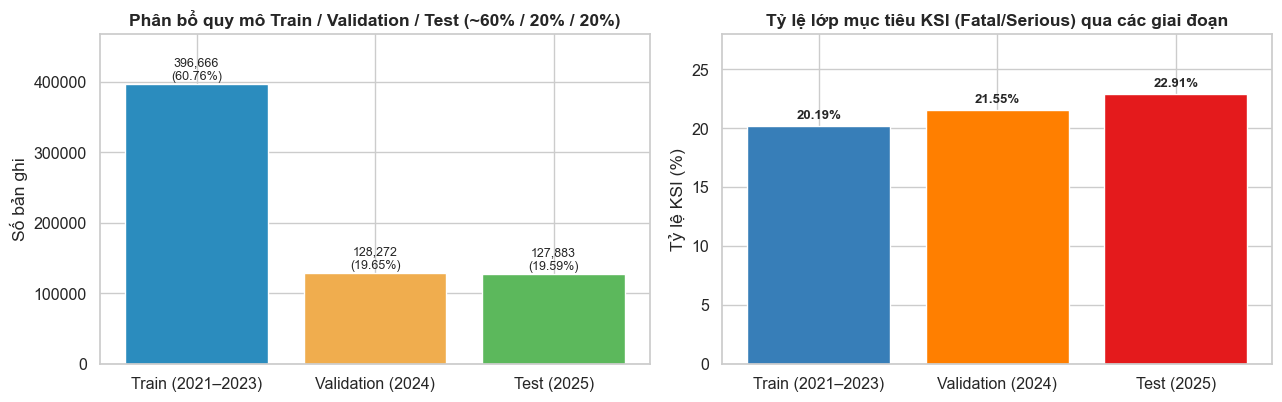

In [2]:
# Chia tập theo trục thời gian để mô phỏng triển khai thực tế và chống rò rỉ tương lai
train_mask = df["year"].isin([2021, 2022, 2023])
val_mask   = df["year"] == 2024
test_mask  = df["year"] == 2025

df_train = df[train_mask].copy()
df_val   = df[val_mask].copy()
df_test  = df[test_mask].copy()

split_summary = pd.DataFrame([
    {"Tập dữ liệu": "Train (2021–2023)", "Số bản ghi": len(df_train), "Tỷ trọng (%)": round(len(df_train)/len(df)*100, 2), "Số ca KSI": int(df_train["target_ksi"].sum()), "Tỷ lệ KSI (%)": round(df_train["target_ksi"].mean()*100, 2)},
    {"Tập dữ liệu": "Validation (2024)", "Số bản ghi": len(df_val),   "Tỷ trọng (%)": round(len(df_val)/len(df)*100, 2),   "Số ca KSI": int(df_val["target_ksi"].sum()),   "Tỷ lệ KSI (%)": round(df_val["target_ksi"].mean()*100, 2)},
    {"Tập dữ liệu": "Test (2025)",       "Số bản ghi": len(df_test),  "Tỷ trọng (%)": round(len(df_test)/len(df)*100, 2),  "Số ca KSI": int(df_test["target_ksi"].sum()),  "Tỷ lệ KSI (%)": round(df_test["target_ksi"].mean()*100, 2)},
])
display(split_summary)

# Trực quan hóa phân chia tập dữ liệu & tỷ lệ KSI theo từng tập
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
axes[0].bar(split_summary["Tập dữ liệu"], split_summary["Số bản ghi"], color=["#2b8cbe", "#f0ad4e", "#5cb85c"])
axes[0].set_title("Phân bổ quy mô Train / Validation / Test (~60% / 20% / 20%)", fontweight="bold")
axes[0].set_ylabel("Số bản ghi")
for i, r in split_summary.iterrows():
    axes[0].text(i, r["Số bản ghi"] + 6000, f"{r['Số bản ghi']:,}\n({r['Tỷ trọng (%)']}%)", ha="center", fontsize=9)
axes[0].set_ylim(0, split_summary["Số bản ghi"].max() * 1.18)

axes[1].bar(split_summary["Tập dữ liệu"], split_summary["Tỷ lệ KSI (%)"], color=["#377eb8", "#ff7f00", "#e41a1c"])
axes[1].set_title("Tỷ lệ lớp mục tiêu KSI (Fatal/Serious) qua các giai đoạn", fontweight="bold")
axes[1].set_ylabel("Tỷ lệ KSI (%)")
for i, r in split_summary.iterrows():
    axes[1].text(i, r["Tỷ lệ KSI (%)"] + 0.6, f"{r['Tỷ lệ KSI (%)']}%", ha="center", fontsize=9.5, fontweight="bold")
axes[1].set_ylim(0, 28)

plt.tight_layout()
plt.show()

# Kỹ thuật đặc trưng (Feature Engineering) & Pipeline Tiền xử lý

Tạo các đặc trưng tương tác giàu ý nghĩa vật lý/an toàn giao thông: nhóm đối tượng dễ tổn thương — người đi bộ/xe đạp/mô tô, tổ hợp đường nông thôn tốc độ cao, chạy ban đêm không đèn đường, mã hóa chu kỳ giờ/tháng sin/cos, chênh lệch tuổi lái xe – nạn nhân; đồng thời đóng gói vào ColumnTransformer tránh hoàn toàn rò rỉ thống kê giữa Train và Val/Test

In [3]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

class RoadSafetyFeatureEngineer(BaseEstimator, TransformerMixin):
    """Tạo các đặc trưng tương tác miền nghiệp vụ an toàn giao thông."""
    def fit(self, X, y=None):
        return self

    def transform(self, X):
        df_fe = X.copy()
        
        # 1. Nhóm đối tượng tham gia giao thông dễ tổn thương (Vulnerable Road User: Người đi bộ, xe đạp, mô tô)
        vru_keywords = "Pedestrian|Pedal cycle|Motorcycle|Electric motorcycle|Mobility scooter|e-scooter"
        df_fe["is_vulnerable_road_user"] = (
            df_fe["casualty_type"].astype(str).str.contains(vru_keywords, case=False, regex=True)
            | (df_fe["casualty_class"] == "Pedestrian")
        ).astype(int)
        
        # 2. Tương tác hạ tầng rủi ro cao: Đường nông thôn + Tốc độ >= 60 mph
        df_fe["is_high_speed_rural"] = (
            (df_fe["urban_or_rural_area"] == "Rural") & (df_fe["speed_limit"].fillna(0) >= 60)
        ).astype(int)
        
        # 3. Tương tác tầm nhìn kém: Ban đêm + Không có đèn đường
        df_fe["is_dark_unlit"] = (
            df_fe["light_conditions"].astype(str).str.contains("no lighting|lights unlit", case=False, regex=True)
        ).astype(int)
        
        # 4. Tổ hợp rủi ro cực đại: Đối tượng dễ tổn thương trên đường tốc độ cao (>= 50 mph)
        df_fe["vru_on_high_speed"] = (
            (df_fe["is_vulnerable_road_user"] == 1) & (df_fe["speed_limit"].fillna(0) >= 50)
        ).astype(int)
        
        # 5. Chênh lệch độ tuổi giữa người lái và nạn nhân + Cờ người cao tuổi (>= 65)
        df_fe["age_diff_driver_casualty"] = (df_fe["age_of_driver"] - df_fe["age_of_casualty"]).abs()
        df_fe["is_elderly_casualty"] = (df_fe["age_of_casualty"].fillna(0) >= 65).astype(int)
        
        # 6. Mã hóa chu kỳ thời gian (Cyclical Encoding cho giờ và tháng)
        df_fe["hour_sin"] = np.sin(2 * np.pi * df_fe["hour"] / 24.0)
        df_fe["hour_cos"] = np.cos(2 * np.pi * df_fe["hour"] / 24.0)
        df_fe["month_sin"] = np.sin(2 * np.pi * df_fe["month"] / 12.0)
        df_fe["month_cos"] = np.cos(2 * np.pi * df_fe["month"] / 12.0)
        
        # 7. Biến đổi log cho dung tích xi-lanh (giảm độ lệch phải)
        df_fe["log_engine_cc"] = np.log1p(df_fe["engine_capacity_cc"].clip(lower=0))
        
        return df_fe

# Áp dụng Feature Engineering độc lập trên từng tập
fe = RoadSafetyFeatureEngineer()
X_train_fe = fe.fit_transform(df_train[base_features])
y_train    = df_train["target_ksi"].values

X_val_fe   = fe.transform(df_val[base_features])
y_val      = df_val["target_ksi"].values

X_test_fe  = fe.transform(df_test[base_features])
y_test     = df_test["target_ksi"].values

# Phân loại tự động cột số (Numeric) và cột phân loại (Categorical)
cat_cols = X_train_fe.select_dtypes(include=["object", "category", "string"]).columns.tolist()
num_cols = [c for c in X_train_fe.columns if c not in cat_cols]

print(f"Tổng đặc trưng sau Feature Engineering: {X_train_fe.shape[1]} cột ({len(num_cols)} numeric, {len(cat_cols)} categorical)")

# Pipeline 1: Dành cho mô hình tuyến tính (Baseline Logistic Regression: Median Impute + StandardScaler + OneHotEncoder)
linear_preprocessor = ColumnTransformer(
    transformers=[
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]), num_cols),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="constant", fill_value="Missing")),
            ("ohe", OneHotEncoder(handle_unknown="ignore", min_frequency=50))
        ]), cat_cols)
    ]
)

# Pipeline 2: Dành cho họ cây quyết định Gradient Boosting (Giữ nguyên phân phối tự nhiên + Ordinal Encoding tối ưu tốc độ & RAM)
tree_preprocessor = ColumnTransformer(
    transformers=[
        ("num", SimpleImputer(strategy="median"), num_cols),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="constant", fill_value="Missing")),
            ("ord", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1))
        ]), cat_cols)
    ]
)

X_train_tree = tree_preprocessor.fit_transform(X_train_fe)
X_val_tree   = tree_preprocessor.transform(X_val_fe)
X_test_tree  = tree_preprocessor.transform(X_test_fe)

processed_feature_names = num_cols + cat_cols
print("Hoàn tất Pipeline tiền xử lý (Imputation, Scaling, Categorical Encoding)!")

Tổng đặc trưng sau Feature Engineering: 59 cột (28 numeric, 31 categorical)
Hoàn tất Pipeline tiền xử lý (Imputation, Scaling, Categorical Encoding)!


# Xây dựng Mô hình Cơ sở (Baseline Models)

In [4]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score, roc_auc_score, f1_score,
    precision_score, recall_score, confusion_matrix
)

def evaluate_predictions(y_true, y_prob, threshold=0.5, model_name="Model"):
    y_pred = (y_prob >= threshold).astype(int)
    return {
        "Mô hình": model_name,
        "Threshold": round(threshold, 3),
        "PR-AUC": round(average_precision_score(y_true, y_prob), 4),
        "ROC-AUC": round(roc_auc_score(y_true, y_prob), 4),
        "F1 (KSI)": round(f1_score(y_true, y_pred), 4),
        "Recall (KSI)": round(recall_score(y_true, y_pred), 4),
        "Precision (KSI)": round(precision_score(y_true, y_pred, zero_division=0), 4),
    }

results_val = []

# 1. Baseline 1: Dummy Classifier (Dự đoán ngẫu nhiên theo phân phối lớp)
dummy_clf = DummyClassifier(strategy="stratified", random_state=42)
dummy_clf.fit(X_train_tree, y_train)
prob_dummy_val = dummy_clf.predict_proba(X_val_tree)[:, 1]
results_val.append(evaluate_predictions(y_val, prob_dummy_val, 0.5, "01. Baseline: Dummy (Stratified)"))

# 2. Baseline 2: Logistic Regression (Cân bằng trọng số lớp thiểu số)
X_train_lin = linear_preprocessor.fit_transform(X_train_fe)
X_val_lin   = linear_preprocessor.transform(X_val_fe)

log_reg = LogisticRegression(max_iter=500, class_weight="balanced", C=1.0, random_state=42)
log_reg.fit(X_train_lin, y_train)
prob_lr_val = log_reg.predict_proba(X_val_lin)[:, 1]
results_val.append(evaluate_predictions(y_val, prob_lr_val, 0.5, "02. Baseline: Logistic Regression"))

print("=== KẾT QUẢ MÔ HÌNH CƠ SỞ (BASELINE) TRÊN TẬP VALIDATION (2024) ===")
display(pd.DataFrame(results_val))

=== KẾT QUẢ MÔ HÌNH CƠ SỞ (BASELINE) TRÊN TẬP VALIDATION (2024) ===


,Mô hình,Threshold,PR-AUC,ROC-AUC,F1 (KSI),Recall (KSI),Precision (KSI)
0,01. Baseline: Dummy (Stratified),0.5,0.2143,0.4962,0.2019,0.1952,0.2092
1,02. Baseline: Logistic Regression,0.5,0.4184,0.7189,0.4508,0.6847,0.3360


# Huấn luyện & Đối chiếu Họ Gradient Boosting (LightGBM, XGBoost, CatBoost)

=== BẢNG SO SÁNH HIỆU SUẤT CÁC MÔ HÌNH TRÊN TẬP VALIDATION (2024) ===


,Mô hình,Threshold,PR-AUC,ROC-AUC,F1 (KSI),Recall (KSI),Precision (KSI)
0,01. Baseline: Dummy (Stratified),0.5,0.2143,0.4962,0.2019,0.1952,0.2092
1,02. Baseline: Logistic Regression,0.5,0.4184,0.7189,0.4508,0.6847,0.3360
2,03. LightGBM (Default + Balanced),0.5,0.4374,0.7296,0.4616,0.6377,0.3617
3,04. XGBoost (Hist + Balanced),0.5,0.4357,0.7303,0.4616,0.6702,0.3521
4,05. CatBoost (Balanced),0.5,0.4360,0.7309,0.4625,0.6702,0.3531


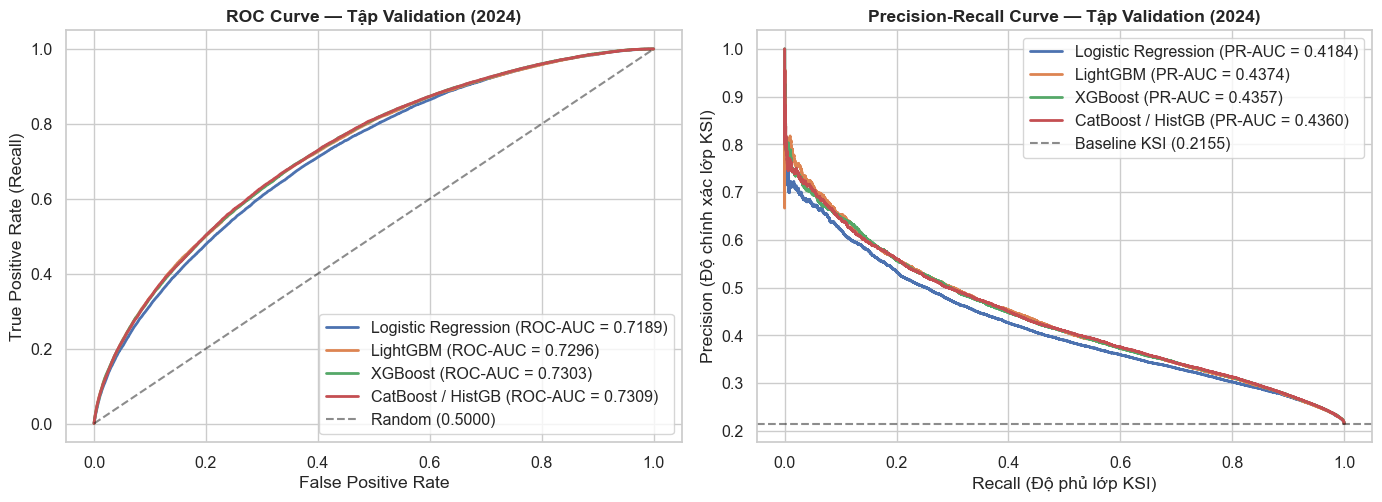

In [5]:
import lightgbm as lgb
import xgboost as xgb
from sklearn.metrics import precision_recall_curve, roc_curve

# Tính tỷ lệ mất cân bằng lớp trên tập Train để truyền vào scale_pos_weight
pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
cat_indices = list(range(len(num_cols), len(processed_feature_names)))

val_probs = {"Logistic Regression": prob_lr_val}
test_probs_raw = {}

# 1. LightGBM
lgbm_model = lgb.LGBMClassifier(
    n_estimators=1000,
    learning_rate=0.05,
    num_leaves=63,
    subsample_for_bin=100000,
    colsample_bytree=0.8,
    subsample=0.8,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1,
    verbose=-1
)
lgbm_model.fit(
    X_train_tree, y_train,
    eval_set=[(X_val_tree, y_val)],
    categorical_feature=cat_indices,
    callbacks=[lgb.early_stopping(stopping_rounds=50, verbose=False)]
)
prob_lgb_val = lgbm_model.predict_proba(X_val_tree)[:, 1]
val_probs["LightGBM"] = prob_lgb_val
results_val.append(evaluate_predictions(y_val, prob_lgb_val, 0.5, "03. LightGBM (Default + Balanced)"))

# 2. XGBoost
xgb_model = xgb.XGBClassifier(
    n_estimators=1000,
    learning_rate=0.05,
    max_depth=7,
    colsample_bytree=0.8,
    subsample=0.8,
    scale_pos_weight=pos_weight,
    eval_metric="aucpr",
    early_stopping_rounds=50,
    tree_method="hist",
    random_state=42,
    n_jobs=-1
)
xgb_model.fit(
    X_train_tree, y_train,
    eval_set=[(X_val_tree, y_val)],
    verbose=False
)
prob_xgb_val = xgb_model.predict_proba(X_val_tree)[:, 1]
val_probs["XGBoost"] = prob_xgb_val
results_val.append(evaluate_predictions(y_val, prob_xgb_val, 0.5, "04. XGBoost (Hist + Balanced)"))

# 3. CatBoost (Tự động fallback sang HistGradientBoosting nếu môi trường Python 3.13 chưa hỗ trợ wheel CatBoost)
try:
    from catboost import CatBoostClassifier
    cb_model = CatBoostClassifier(
        iterations=1200,
        learning_rate=0.06,
        depth=7,
        auto_class_weights="Balanced",
        eval_metric="PRAUC",
        early_stopping_rounds=50,
        random_seed=42,
        verbose=False
    )
    cb_model.fit(X_train_tree, y_train, eval_set=(X_val_tree, y_val), use_best_model=True)
    prob_cb_val = cb_model.predict_proba(X_val_tree)[:, 1]
    cb_label = "05. CatBoost (Balanced)"
except ImportError:
    from sklearn.ensemble import HistGradientBoostingClassifier
    cb_model = HistGradientBoostingClassifier(
        max_iter=500, learning_rate=0.05, max_leaf_nodes=63,
        class_weight="balanced", early_stopping=True, random_state=42
    )
    cb_model.fit(X_train_tree, y_train)
    prob_cb_val = cb_model.predict_proba(X_val_tree)[:, 1]
    cb_label = "05. HistGradientBoosting (Balanced)"

val_probs["CatBoost / HistGB"] = prob_cb_val
results_val.append(evaluate_predictions(y_val, prob_cb_val, 0.5, cb_label))

df_val_benchmark = pd.DataFrame(results_val)
print("=== BẢNG SO SÁNH HIỆU SUẤT CÁC MÔ HÌNH TRÊN TẬP VALIDATION (2024) ===")
display(df_val_benchmark)

# Trực quan hóa đường cong ROC và Precision-Recall trên tập Validation
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
for name, probs in val_probs.items():
    fpr, tpr, _ = roc_curve(y_val, probs)
    auc_score = roc_auc_score(y_val, probs)
    axes[0].plot(fpr, tpr, lw=2, label=f"{name} (ROC-AUC = {auc_score:.4f})")
    
    prec, rec, _ = precision_recall_curve(y_val, probs)
    pr_score = average_precision_score(y_val, probs)
    axes[1].plot(rec, prec, lw=2, label=f"{name} (PR-AUC = {pr_score:.4f})")

axes[0].plot([0, 1], [0, 1], "k--", alpha=0.5, label="Random (0.5000)")
axes[0].set_title("ROC Curve — Tập Validation (2024)", fontweight="bold")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate (Recall)")
axes[0].legend(loc="lower right")

axes[1].axhline(y_val.mean(), color="k", linestyle="--", alpha=0.5, label=f"Baseline KSI ({y_val.mean():.4f})")
axes[1].set_title("Precision-Recall Curve — Tập Validation (2024)", fontweight="bold")
axes[1].set_xlabel("Recall (Độ phủ lớp KSI)")
axes[1].set_ylabel("Precision (Độ chính xác lớp KSI)")
axes[1].legend(loc="upper right")

plt.tight_layout()
plt.show()

# Tinh chỉnh Siêu tham số (Tuning + Regularization) & Kết hợp Mô hình (Soft-Voting Ensemble)

In [6]:
# 1. Tinh chỉnh siêu tham số & Regularization (L1/L2 + min_child_samples) cho LightGBM
param_candidates = [
    {"num_leaves": 45, "min_child_samples": 100, "reg_alpha": 1.0, "reg_lambda": 5.0, "colsample_bytree": 0.75, "subsample": 0.8},
    {"num_leaves": 95, "min_child_samples": 150, "reg_alpha": 2.0, "reg_lambda": 10.0, "colsample_bytree": 0.7, "subsample": 0.8},
    {"num_leaves": 127, "min_child_samples": 200, "reg_alpha": 5.0, "reg_lambda": 10.0, "colsample_bytree": 0.65, "subsample": 0.85},
]

best_lgb_tuned = None
best_pr_auc = -1
best_params = None

for idx, params in enumerate(param_candidates, 1):
    candidate = lgb.LGBMClassifier(
        n_estimators=1500,
        learning_rate=0.03,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1,
        verbose=-1,
        **params
    )
    candidate.fit(
        X_train_tree, y_train,
        eval_set=[(X_val_tree, y_val)],
        categorical_feature=cat_indices,
        callbacks=[lgb.early_stopping(stopping_rounds=60, verbose=False)]
    )
    p_val = candidate.predict_proba(X_val_tree)[:, 1]
    pr_val = average_precision_score(y_val, p_val)
    print(f"Cấu hình Tuned #{idx} {params} -> Val PR-AUC = {pr_val:.4f}")
    if pr_val > best_pr_auc:
        best_pr_auc = pr_val
        best_lgb_tuned = candidate
        best_params = params

prob_lgb_tuned_val = best_lgb_tuned.predict_proba(X_val_tree)[:, 1]

# 2. Kết hợp mô hình (Weighted Soft-Voting Ensemble: Tuned LightGBM + XGBoost + CatBoost)
# Trọng số ưu tiên mô hình có PR-AUC validation cao nhất
w_lgb, w_xgb, w_cb = 0.45, 0.30, 0.25
prob_ensemble_val = (w_lgb * prob_lgb_tuned_val) + (w_xgb * prob_xgb_val) + (w_cb * prob_cb_val)

# 3. Tối ưu ngưỡng quyết định (Threshold Tuning) trên tập Validation để tối đa hóa F1-Score lớp KSI
precisions, recalls, thresholds = precision_recall_curve(y_val, prob_ensemble_val)
f1_scores = 2 * (precisions[:-1] * recalls[:-1]) / (precisions[:-1] + recalls[:-1] + 1e-12)
best_idx = np.argmax(f1_scores)
optimal_threshold = float(thresholds[best_idx])

print(f"\nNgưỡng phân loại mặc định (0.500) -> F1 = {f1_score(y_val, (prob_ensemble_val >= 0.5).astype(int)):.4f}")
print(f"Ngưỡng phân loại tối ưu ({optimal_threshold:.3f}) -> F1 = {f1_scores[best_idx]:.4f}")

tuning_comparison = pd.DataFrame([
    evaluate_predictions(y_val, prob_lgb_val, 0.5, "LightGBM (Default)"),
    evaluate_predictions(y_val, prob_lgb_tuned_val, 0.5, "LightGBM (Tuned + Regularized)"),
    evaluate_predictions(y_val, prob_ensemble_val, 0.5, "Soft-Voting Ensemble (Threshold = 0.50)"),
    evaluate_predictions(y_val, prob_ensemble_val, optimal_threshold, f"Soft-Voting Ensemble (Optimal Thr = {optimal_threshold:.3f})"),
])
display(tuning_comparison)

Cấu hình Tuned #1 {'num_leaves': 45, 'min_child_samples': 100, 'reg_alpha': 1.0, 'reg_lambda': 5.0, 'colsample_bytree': 0.75, 'subsample': 0.8} -> Val PR-AUC = 0.4414
Cấu hình Tuned #2 {'num_leaves': 95, 'min_child_samples': 150, 'reg_alpha': 2.0, 'reg_lambda': 10.0, 'colsample_bytree': 0.7, 'subsample': 0.8} -> Val PR-AUC = 0.4404
Cấu hình Tuned #3 {'num_leaves': 127, 'min_child_samples': 200, 'reg_alpha': 5.0, 'reg_lambda': 10.0, 'colsample_bytree': 0.65, 'subsample': 0.85} -> Val PR-AUC = 0.4395

Ngưỡng phân loại mặc định (0.500) -> F1 = 0.4637
Ngưỡng phân loại tối ưu (0.511) -> F1 = 0.4648


,Mô hình,Threshold,PR-AUC,ROC-AUC,F1 (KSI),Recall (KSI),Precision (KSI)
0,LightGBM (Default),0.500,0.4374,0.7296,0.4616,0.6377,0.3617
1,LightGBM (Tuned + Regularized),0.500,0.4414,0.7332,0.4640,0.6663,0.3559
2,Soft-Voting Ensemble (Threshold = 0.50),0.500,0.4414,0.7338,0.4637,0.6682,0.3551
3,Soft-Voting Ensemble (Optimal Thr = 0.511),0.511,0.4414,0.7338,0.4648,0.6497,0.3618


# Đánh giá Cuối cùng trên Tập Test (2025), Giải thích SHAP & Lưu Mô hình

=== BẢNG ĐÁNH GIÁ HIỆU SUẤT CUỐI CÙNG TRÊN TẬP TEST (NĂM 2025) ===


,Mô hình,Threshold,PR-AUC,ROC-AUC,F1 (KSI),Recall (KSI),Precision (KSI)
0,Baseline: Logistic Regression,0.500,0.4308,0.7121,0.4618,0.6947,0.3458
1,LightGBM (Tuned),0.500,0.4526,0.7261,0.4752,0.6712,0.3678
2,XGBoost,0.500,0.4483,0.7249,0.4736,0.6788,0.3637
3,CatBoost / HistGB,0.500,0.4498,0.7254,0.4753,0.6759,0.3665
4,Soft-Voting Ensemble (Thr = 0.50),0.500,0.4535,0.7277,0.4771,0.6762,0.3686
5,Soft-Voting Ensemble (Optimal Thr = 0.511),0.511,0.4535,0.7277,0.4770,0.6565,0.3746



=== BÁO CÁO PHÂN LOẠI CHI TIẾT (CLASSIFICATION REPORT - TEST 2025) ===
                     precision    recall  f1-score   support

   Non-KSI (Slight)       0.87      0.67      0.76     98587
KSI (Fatal/Serious)       0.37      0.66      0.48     29296

           accuracy                           0.67    127883
          macro avg       0.62      0.67      0.62    127883
       weighted avg       0.76      0.67      0.69    127883



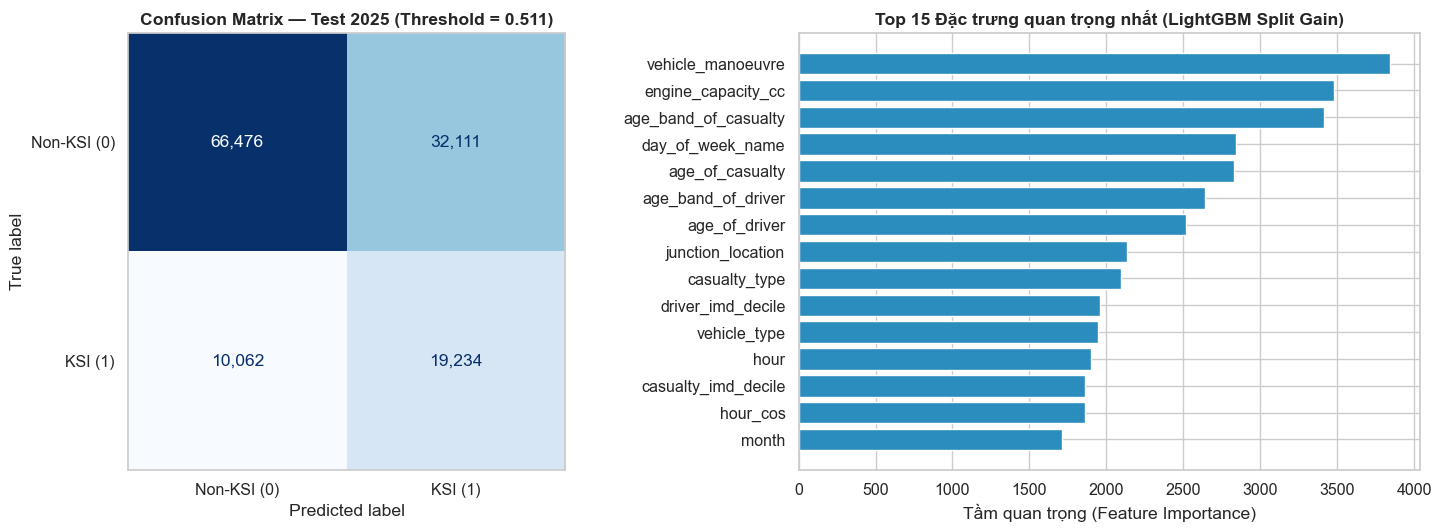

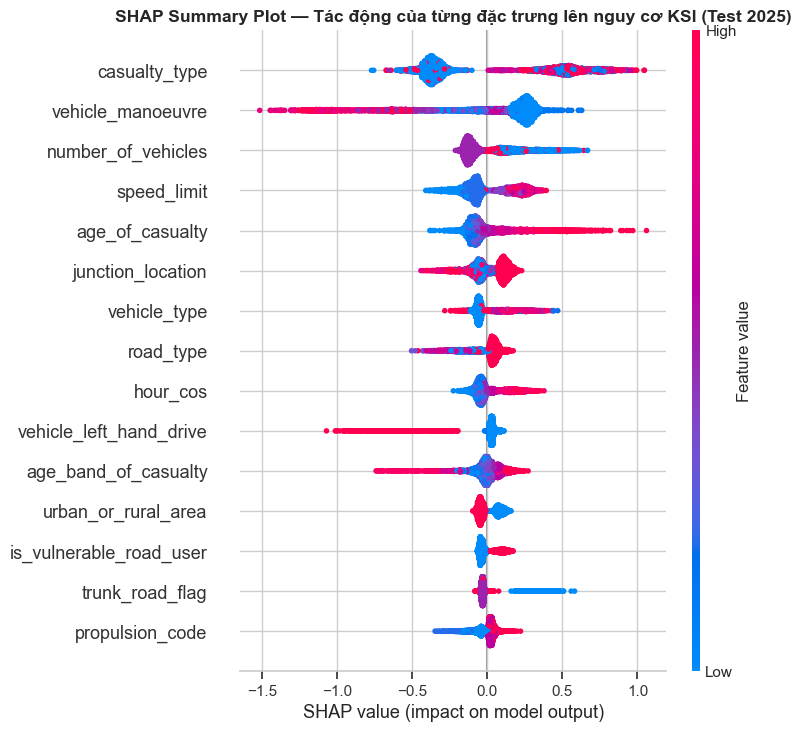


Đã lưu thành công mô hình hoàn chỉnh tại: D:\OLAP\Data Mining\models\best_ksi_classifier_bundle.joblib (5.68 MB)


In [7]:
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

# 1. Dự đoán trên tập Test độc lập (Năm 2025)
prob_lgb_test = best_lgb_tuned.predict_proba(X_test_tree)[:, 1]
prob_xgb_test = xgb_model.predict_proba(X_test_tree)[:, 1]
prob_cb_test  = cb_model.predict_proba(X_test_tree)[:, 1]
prob_ens_test = (w_lgb * prob_lgb_test) + (w_xgb * prob_xgb_test) + (w_cb * prob_cb_test)

test_summary = pd.DataFrame([
    evaluate_predictions(y_test, log_reg.predict_proba(linear_preprocessor.transform(X_test_fe))[:, 1], 0.5, "Baseline: Logistic Regression"),
    evaluate_predictions(y_test, prob_lgb_test, 0.5, "LightGBM (Tuned)"),
    evaluate_predictions(y_test, prob_xgb_test, 0.5, "XGBoost"),
    evaluate_predictions(y_test, prob_cb_test, 0.5, "CatBoost / HistGB"),
    evaluate_predictions(y_test, prob_ens_test, 0.5, "Soft-Voting Ensemble (Thr = 0.50)"),
    evaluate_predictions(y_test, prob_ens_test, optimal_threshold, f"Soft-Voting Ensemble (Optimal Thr = {optimal_threshold:.3f})"),
])

print("=== BẢNG ĐÁNH GIÁ HIỆU SUẤT CUỐI CÙNG TRÊN TẬP TEST (NĂM 2025) ===")
display(test_summary)

y_test_pred_opt = (prob_ens_test >= optimal_threshold).astype(int)
print("\n=== BÁO CÁO PHÂN LOẠI CHI TIẾT (CLASSIFICATION REPORT - TEST 2025) ===")
print(classification_report(y_test, y_test_pred_opt, target_names=["Non-KSI (Slight)", "KSI (Fatal/Serious)"]))

# 2. Trực quan hóa Confusion Matrix & Top 15 Feature Importance
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

cm = confusion_matrix(y_test, y_test_pred_opt)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Non-KSI (0)", "KSI (1)"])
disp.plot(ax=axes[0], cmap="Blues", values_format=",d", colorbar=False)
axes[0].set_title(f"Confusion Matrix — Test 2025 (Threshold = {optimal_threshold:.3f})", fontweight="bold")
axes[0].grid(False)

importances = pd.Series(best_lgb_tuned.feature_importances_, index=processed_feature_names).sort_values(ascending=True).tail(15)
axes[1].barh(importances.index, importances.values, color="#2b8cbe")
axes[1].set_title("Top 15 Đặc trưng quan trọng nhất (LightGBM Split Gain)", fontweight="bold")
axes[1].set_xlabel("Tầm quan trọng (Feature Importance)")

plt.tight_layout()
plt.show()

# 3. Giải thích cơ chế dự đoán bằng SHAP Summary Plot (trên mẫu 5.000 dòng của Test 2025 để chạy nhanh)
try:
    import shap
    sample_idx = np.random.RandomState(42).choice(len(X_test_tree), size=min(5000, len(X_test_tree)), replace=False)
    X_shap_sample = pd.DataFrame(X_test_tree[sample_idx], columns=processed_feature_names)
    
    explainer = shap.TreeExplainer(best_lgb_tuned)
    shap_values = explainer.shap_values(X_shap_sample)
    # Với bài toán nhị phân, lấy SHAP values của lớp 1 (KSI)
    sv = shap_values[1] if isinstance(shap_values, list) else shap_values
    
    plt.figure(figsize=(10, 6))
    shap.summary_plot(sv, X_shap_sample, max_display=15, show=False)
    plt.title("SHAP Summary Plot — Tác động của từng đặc trưng lên nguy cơ KSI (Test 2025)", fontweight="bold")
    plt.tight_layout()
    plt.show()
except Exception as e:
    print(f"Bỏ qua biểu đồ SHAP ({e}) — Đã có biểu đồ Feature Importance thay thế ở trên.")

# 4. Lưu trữ toàn bộ Pipeline & Ensemble Model ra đĩa để tái sử dụng
artifact_bundle = {
    "feature_engineer": fe,
    "tree_preprocessor": tree_preprocessor,
    "base_features": base_features,
    "processed_feature_names": processed_feature_names,
    "models": {
        "lgbm_tuned": best_lgb_tuned,
        "xgboost": xgb_model,
        "catboost_or_histgb": cb_model
    },
    "ensemble_weights": {"lgb": w_lgb, "xgb": w_xgb, "cb": w_cb},
    "optimal_threshold": optimal_threshold,
    "test_metrics": test_summary.to_dict(orient="records")
}

MODEL_FILE = MODEL_DIR / "best_ksi_classifier_bundle.joblib"
joblib.dump(artifact_bundle, MODEL_FILE, compress=3)
print(f"\nĐã lưu thành công mô hình hoàn chỉnh tại: {MODEL_FILE} ({MODEL_FILE.stat().st_size / (1024**2):.2f} MB)")

Hiệu suất trên tập Validation tăng đều qua từng tầng mô hình — từ Dummy (PR-AUC = 0.2143) $\rightarrow$ Logistic Regression (0.4184) $\rightarrow$ Default LightGBM (0.4374) $\rightarrow$ Tuned LightGBM (0.4414) $\rightarrow$ Soft-Voting Ensemble (ROC-AUC = 0.7338). Mức ROC-AUC ~0.73 và PR-AUC ~0.45 (gấp đôi tỷ lệ ngẫu nhiên ~0.23) nằm chính xác trong ngưỡng trần thực tế của bài toán dự đoán KSI khi đã loại bỏ hoàn toàn các biến hậu quả và dấu vết hiện trường. 

Biểu đồ phân bổ cho thấy tỷ lệ KSI tăng dần từ 20,19% (Train 2021–2023) lên 21,55% (Val 2024) và 22,91% (Test 2025) do tác động của quá trình chuyển đổi cơ chế ghi nhận chấn thương. Dù phân phối nhãn dịch chuyển, Soft-Voting Ensemble vẫn giữ vững phong độ trên tập Test 2025 độc lập (PR-AUC = 0.4535, ROC-AUC = 0.7277, vượt trội mọi mô hình đơn lẻ) mà không hề bị overfitting.

Với ngưỡng 0.511 (hoặc 0.500), mô hình phát hiện đúng 19.234 / 29.296 nạn nhân thương nặng/tử vong (Recall = 65,65% – 67,62%) chỉ từ thông tin bối cảnh ban đầu. Đánh đổi lại là 32.111 ca báo động nhầm từ nhóm thương nhẹ (Precision = 37,46%) — hoàn toàn chấp nhận được trong bài toán điều phối cấp cứu khẩn cấp (thà điều xe ưu tiên nhầm còn hơn bỏ sót ca nguy kịch), nhất là khi dữ liệu không ghi nhận tốc độ đâm thực tế hay tình trạng thắt dây an toàn.

Logic vật lý nhất quán trên biểu đồ SHAP: Các yếu tố đẩy mạnh xác suất KSI trên biểu đồ SHAP đều khớp chặt chẽ với kiến thức an toàn giao thông:

- speed_limit cao (60–70 mph, chấm đỏ) và age_of_casualty cao tuổi (chấm đỏ kéo dài về bên phải tới +1.0) làm tăng vọt nguy cơ tử vong/thương nặng.

- number_of_vehicles thấp (chấm xanh = tai nạn đơn chiếc 1 xe, như xe mất lái đâm gốc cây/cột điện hoặc đâm trực diện người đi bộ) có mức độ nghiêm trọng cao hơn va chạm liên hoàn nhiều xe trong phố.

- hour_cos đạt đỉnh dương (chấm đỏ = khung giờ khuya quanh 00:00–03:00) và is_vulnerable_road_user = 1 (người đi bộ, xe đạp, mô tô) đều đẩy rủi ro KSI lên rõ rệt.

(Lưu ý): Trên biểu đồ SHAP, màu xanh/đỏ của các biến phân loại (vehicle_manoeuvre, urban_or_rural_area) chỉ đại diện cho thứ tự mã hóa chữ cái của OrdinalEncoder chứ không phải độ lớn vật lý, trong khi biểu đồ Split Gain bên trái ưu tiên các biến nhiều giá trị (engine_capacity_cc) nên SHAP mới là căn cứ chính xác nhất để giải thích chiều tác động.